In [5]:
# ==============================================================================
# Tester with active-bundle variants added to the paper plots
# ==============================================================================
# Produces four panels:
#   1. Staircase max-affine objective gap, including KLM active bundle
#   2. Low-rank least-squares objective gap, including SPPPA active bundle
#   3. Structured rotated Lasso objective gap with inexact prox solves, including SPPPA active bundle
#   4. Theoretical accumulated error terms for the inexact prox test, including SPPPA active bundle

using LinearAlgebra
using Random
using Printf
using Plots
using Convex
import SCS
import MathOptInterface as MOI

include("BasicDefinitions_v5.jl")
include("KLM.jl")
include("KLM_active.jl")
include("OPPA.jl")
include("SPPPA.jl")
include("SPPPA_active.jl")

# ------------------------------------------------------------------------------
# Helpers
# ------------------------------------------------------------------------------

function gaps(obj_hist::Vector{Float64}, f_star::Float64;
              floor_val::Float64=1e-14,
              best::Bool=false)
    g = max.(obj_hist .- f_star, floor_val)
    return best ? accumulate(min, g) : g
end

function final_best_gap(obj_hist::Vector{Float64}, f_star::Float64; floor_val::Float64=1e-14)
    return last(gaps(obj_hist, f_star; floor_val=floor_val, best=true))
end

function print_result_table(title::String, rows; has_delta::Bool=false)
    println("\n", title)
    println(repeat("-", length(title)))

    if has_delta
        @printf("%-28s  %12s  %12s  %12s  %12s\n",
                "method", "final gap", "best gap", "delta", "time (s)")
        for row in rows
            name, final_gap, best_gap, delta, t = row
            @printf("%-28s  %12.4e  %12.4e  %12.4e  %12.3f\n",
                    name, final_gap, best_gap, delta, t)
        end
    else
        @printf("%-28s  %12s  %12s  %12s\n",
                "method", "final gap", "best gap", "time (s)")
        for row in rows
            name, final_gap, best_gap, t = row
            @printf("%-28s  %12.4e  %12.4e  %12.3f\n",
                    name, final_gap, best_gap, t)
        end
    end
end

# ------------------------------------------------------------------------------
# OPPA theoretical accumulated error tracking
# ------------------------------------------------------------------------------

function optimize_oppa_certified_delta(prob::RotatedStratifiedLassoProblem,
                                       method::OPPAMethod,
                                       x0::Vector{Float64};
                                       max_iters::Int=80,
                                       cert_iters::Int=1000)
    state = init_state(method, x0)

    obj_history = Float64[evaluate_objective(prob, x0)]
    time_history = Float64[0.0]
    eps_history = Float64[0.0]
    delta_history = Float64[0.0]
    tau_weight_history = Float64[0.0]

    start_time = time_ns()

    for _ in 1:max_iters
        x_query, L = get_query(method, state)
        res = evaluate_oracle(prob, x_query, L)

        eps = estimate_epsilon_subgradient_gap(
            prob, res.y, res.g; cert_iters=cert_iters, x_init=res.y
        )

        state = update!(method, state, res)

        # The OPPA recurrence adds tau_n * eps_n. In this implementation,
        # state.tau_prev is the tau attached to the newly observed y/g pair.
        tau_weight = state.tau_prev
        delta_next = last(delta_history) + tau_weight * eps

        push!(obj_history, evaluate_objective(prob, get_iterate(method, state)))
        push!(time_history, (time_ns() - start_time) / 1e9)
        push!(eps_history, eps)
        push!(delta_history, delta_next)
        push!(tau_weight_history, tau_weight)
    end

    return state, obj_history, time_history, eps_history, delta_history, tau_weight_history
end

# ------------------------------------------------------------------------------
# Fixed-window SPPPA theoretical accumulated error tracking
# ------------------------------------------------------------------------------

mutable struct SPPPAAuxErrorState
    delta_prime::Float64
    memory_delta::Vector{Float64}
    memory_eps::Vector{Float64}
end

init_spppa_aux_error_state() = SPPPAAuxErrorState(0.0, Float64[], Float64[])

function tracked_spppa_update!(method::SPPPAMethod,
                               state::SPPPAState,
                               aux::SPPPAAuxErrorState,
                               res::ProximalResult,
                               eps::Float64)
    if state.frozen
        return aux.delta_prime
    end

    L = method.L

    if state.n == 0
        tau_prev = 2.0 / L
        z_next = state.x0 - tau_prev * res.g
    else
        z_next = state.z_prime - (state.tau_n - state.tau_prime) * res.g
        tau_prev = state.tau_n
    end

    new_delta = aux.delta_prime + tau_prev * eps

    push!(state.history, SPPPAHistory(copy(res.y), res.f_y, copy(res.g), copy(z_next), tau_prev))
    push!(aux.memory_delta, new_delta)
    push!(aux.memory_eps, eps)

    if length(state.history) > method.k
        popfirst!(state.history)
        popfirst!(aux.memory_delta)
        popfirst!(aux.memory_eps)
    end

    W = length(state.history)
    f_vec = [h.f for h in state.history]

    m_idx = argmin(f_vec)
    f_m = f_vec[m_idx]
    y_m = state.history[m_idx].y

    Z = hcat([h.z_next - state.x0 for h in state.history]...)
    G = hcat([h.g for h in state.history]...)
    tau_vec = [h.tau for h in state.history]

    a = zeros(W)
    b = zeros(W)

    for i in 1:W
        h = state.history[i]
        q_i = h.f - dot(h.g, h.y - state.x0)
        a[i] = 0.5 * norm(h.z_next - state.x0)^2 + h.tau * (h.f - f_m)
        b[i] = q_i - f_m
    end

    tau_fallback = tau_vec[end]
    z_fallback = state.x0 + Z[:, end]
    delta_fallback = aux.memory_delta[end]

    tau_prime = tau_fallback
    z_prime = z_fallback
    delta_prime = delta_fallback

    mu = Variable(W)
    lam = Variable(W)

    obj = dot(tau_vec, mu) + sum(lam)

    constraints = Constraint[
        mu >= 0,
        lam >= 0,
        sumsquares(Z * mu - G * lam) <= 2.0 * (dot(a, mu) + dot(b, lam))
    ]

    prob_cvx = maximize(obj, constraints)

    scs_opt = MOI.OptimizerWithAttributes(
        SCS.Optimizer,
        "eps_abs" => 1e-9,
        "eps_rel" => 1e-9,
        "max_iters" => 50000
    )

    solve!(prob_cvx, scs_opt; silent_solver=true)

    if prob_cvx.status == MOI.DUAL_INFEASIBLE ||
       prob_cvx.status == MOI.INFEASIBLE_OR_UNBOUNDED ||
       prob_cvx.status == MOI.OBJECTIVE_LIMIT

        # Safe behavior, matching SPPPA_safe.jl: do not freeze. Keep fallback.
        nothing

    elseif prob_cvx.status == MOI.OPTIMAL || prob_cvx.status == MOI.ALMOST_OPTIMAL
        mu_ev = evaluate(mu)
        lam_ev = evaluate(lam)

        mu_val = max.(0.0, mu_ev === nothing ? zeros(W) : (mu_ev isa Number ? [mu_ev] : vec(mu_ev)))
        lam_val = max.(0.0, lam_ev === nothing ? zeros(W) : (lam_ev isa Number ? [lam_ev] : vec(lam_ev)))

        lhs = 0.5 * norm(Z * mu_val - G * lam_val)^2
        rhs = dot(a, mu_val) + dot(b, lam_val)

        if lhs > rhs
            if rhs > 1e-14
                alpha = rhs / lhs
                mu_val .*= alpha
                lam_val .*= alpha
            else
                mu_val .= 0.0
                lam_val .= 0.0
            end
        end

        tau_opt = dot(tau_vec, mu_val) + sum(lam_val)
        z_candidate = state.x0 + Z * mu_val - G * lam_val
        cert_lhs = 0.5 * norm(Z * mu_val - G * lam_val)^2
        cert_rhs = dot(a, mu_val) + dot(b, lam_val)

        accept_step =
            isfinite(tau_opt) &&
            all(isfinite, z_candidate) &&
            cert_rhs >= -1e-10 &&
            cert_lhs <= cert_rhs + 1e-8 * max(1.0, abs(cert_rhs)) &&
            tau_opt > tau_fallback * (1.0 + 1e-4) + 1e-8

        if accept_step
            tau_prime = tau_opt
            z_prime = z_candidate
            delta_prime = dot(mu_val, aux.memory_delta) + dot(lam_val, aux.memory_eps)
        end
    end

    tau_next = tau_prime + (1.0 + sqrt(1.0 + 2.0 * L * tau_prime)) / L
    x_next = (tau_prime / tau_next) * y_m + ((tau_next - tau_prime) / tau_next) * z_prime

    state.x = x_next
    state.z_prime = z_prime
    state.tau_prime = tau_prime
    state.tau_n = tau_next
    state.y_last = copy(res.y)
    state.n += 1

    aux.delta_prime = max(0.0, delta_prime)
    return aux.delta_prime
end

function optimize_spppa_certified_delta(prob::RotatedStratifiedLassoProblem,
                                        method::SPPPAMethod,
                                        x0::Vector{Float64};
                                        max_iters::Int=80,
                                        cert_iters::Int=1000)
    state = init_state(method, x0)
    aux = init_spppa_aux_error_state()

    obj_history = Float64[evaluate_objective(prob, x0)]
    time_history = Float64[0.0]
    eps_history = Float64[0.0]
    delta_history = Float64[0.0]

    start_time = time_ns()

    for _ in 1:max_iters
        x_query, L = get_query(method, state)
        res = evaluate_oracle(prob, x_query, L)

        eps = estimate_epsilon_subgradient_gap(
            prob, res.y, res.g; cert_iters=cert_iters, x_init=res.y
        )

        delta_prime = tracked_spppa_update!(method, state, aux, res, eps)

        push!(obj_history, evaluate_objective(prob, get_iterate(method, state)))
        push!(time_history, (time_ns() - start_time) / 1e9)
        push!(eps_history, eps)
        push!(delta_history, delta_prime)
    end

    return state, obj_history, time_history, eps_history, delta_history
end

# ------------------------------------------------------------------------------
# Active-bundle SPPPA theoretical accumulated error tracking
# ------------------------------------------------------------------------------

mutable struct SPPPAActiveAuxErrorState
    delta_prime::Float64
    h_delta::Vector{Float64}
    q_eps::Vector{Float64}
end

init_spppa_active_aux_error_state() = SPPPAActiveAuxErrorState(0.0, Float64[], Float64[])

function tracked_spppa_active_update!(method::SPPPAActiveMethod,
                                      state::SPPPAActiveState,
                                      aux::SPPPAActiveAuxErrorState,
                                      res::ProximalResult,
                                      eps::Float64)
    if state.frozen
        return aux.delta_prime
    end

    L = method.L

    if state.n == 0
        tau_prev = 2.0 / L
        z_next = state.x0 - tau_prev * res.g
    else
        z_next = state.z_prime - (state.tau_n - state.tau_prime) * res.g
        tau_prev = state.tau_n
    end

    current_h = SPPPAActiveHHistory(copy(res.y), res.f_y, copy(z_next), tau_prev)
    current_q = SPPPAActiveQHistory(copy(res.y), res.f_y, copy(res.g))

    current_h_delta = aux.delta_prime + tau_prev * eps
    current_q_eps = eps

    h_candidates = [state.h_history; current_h]
    q_candidates = [state.q_history; current_q]
    h_delta_candidates = [aux.h_delta; current_h_delta]
    q_eps_candidates = [aux.q_eps; current_q_eps]

    WH = length(h_candidates)
    WQ = length(q_candidates)

    y_m_any, f_m = spppa_active_best_y_and_f(h_candidates, q_candidates)
    y_m = y_m_any === nothing ? copy(res.y) : copy(y_m_any)

    Z = hcat([h.z_next - state.x0 for h in h_candidates]...)
    G = hcat([q.g for q in q_candidates]...)
    tau_vec = [h.tau for h in h_candidates]

    a = zeros(WH)
    for i in 1:WH
        h = h_candidates[i]
        a[i] = 0.5 * norm(h.z_next - state.x0)^2 + h.tau * (h.f - f_m)
    end

    b = zeros(WQ)
    for j in 1:WQ
        q = q_candidates[j]
        q_j = q.f - dot(q.g, q.y - state.x0)
        b[j] = q_j - f_m
    end

    tau_fallback = tau_prev
    z_fallback = copy(z_next)
    delta_fallback = current_h_delta

    tau_prime = tau_fallback
    z_prime = z_fallback
    delta_prime = delta_fallback
    accepted_step = false

    mu = Variable(WH)
    lam = Variable(WQ)

    obj = dot(tau_vec, mu) + sum(lam)

    constraints = Constraint[
        mu >= 0,
        lam >= 0,
        sumsquares(Z * mu - G * lam) <= 2.0 * (dot(a, mu) + dot(b, lam))
    ]

    prob_cvx = maximize(obj, constraints)

    scs_opt = MOI.OptimizerWithAttributes(
        SCS.Optimizer,
        "eps_abs" => 1e-9,
        "eps_rel" => 1e-9,
        "max_iters" => 50000,
    )

    solve!(prob_cvx, scs_opt; silent_solver=true)

    mu_val = zeros(WH)
    lam_val = zeros(WQ)

    if prob_cvx.status == MOI.DUAL_INFEASIBLE ||
       prob_cvx.status == MOI.INFEASIBLE_OR_UNBOUNDED ||
       prob_cvx.status == MOI.OBJECTIVE_LIMIT

        # Safe behavior: no freeze. Use fallback.
        nothing

    elseif prob_cvx.status == MOI.OPTIMAL || prob_cvx.status == MOI.ALMOST_OPTIMAL
        mu_ev = evaluate(mu)
        lam_ev = evaluate(lam)

        mu_val = max.(0.0, mu_ev === nothing ? zeros(WH) : (mu_ev isa Number ? [mu_ev] : vec(mu_ev)))
        lam_val = max.(0.0, lam_ev === nothing ? zeros(WQ) : (lam_ev isa Number ? [lam_ev] : vec(lam_ev)))

        lhs = 0.5 * norm(Z * mu_val - G * lam_val)^2
        rhs = dot(a, mu_val) + dot(b, lam_val)

        if lhs > rhs
            if rhs > 1e-14
                alpha = rhs / lhs
                mu_val .*= alpha
                lam_val .*= alpha
            else
                mu_val .= 0.0
                lam_val .= 0.0
            end
        end

        tau_opt = dot(tau_vec, mu_val) + sum(lam_val)
        z_candidate = state.x0 + Z * mu_val - G * lam_val

        cert_lhs = 0.5 * norm(Z * mu_val - G * lam_val)^2
        cert_rhs = dot(a, mu_val) + dot(b, lam_val)

        accept_step =
            isfinite(tau_opt) &&
            all(isfinite, z_candidate) &&
            cert_rhs >= -1e-10 &&
            cert_lhs <= cert_rhs + 1e-8 * max(1.0, abs(cert_rhs)) &&
            tau_opt > tau_fallback * (1.0 + method.accept_rel_tol) + method.accept_abs_tol

        if accept_step
            tau_prime = tau_opt
            z_prime = z_candidate
            delta_prime = dot(mu_val, h_delta_candidates) + dot(lam_val, q_eps_candidates)
            accepted_step = true
        end
    else
        @warn "SPPPAActive planning subproblem failed; using OPPA fallback" iteration=state.n status=prob_cvx.status
    end

    if accepted_step
        active_h = spppa_active_multiplier_indices(mu_val, method.active_tol)
        active_q = spppa_active_multiplier_indices(lam_val, method.active_tol)

        if isempty(active_h) && maximum(mu_val) > 0.0
            push!(active_h, argmax(mu_val))
        end
        if isempty(active_q) && maximum(lam_val) > 0.0
            push!(active_q, argmax(lam_val))
        end

        state.h_history = [h_candidates[i] for i in active_h]
        state.q_history = [q_candidates[j] for j in active_q]
        aux.h_delta = [h_delta_candidates[i] for i in active_h]
        aux.q_eps = [q_eps_candidates[j] for j in active_q]
    else
        state.h_history = SPPPAActiveHHistory[current_h]
        state.q_history = SPPPAActiveQHistory[current_q]
        aux.h_delta = Float64[current_h_delta]
        aux.q_eps = Float64[current_q_eps]
    end

    tau_next = tau_prime + (1.0 + sqrt(1.0 + 2.0 * L * tau_prime)) / L
    x_next = (tau_prime / tau_next) * y_m + ((tau_next - tau_prime) / tau_next) * z_prime

    state.x = x_next
    state.z_prime = z_prime
    state.tau_prime = tau_prime
    state.tau_n = tau_next
    state.y_last = copy(res.y)
    state.n += 1

    aux.delta_prime = max(0.0, delta_prime)
    return aux.delta_prime
end

function optimize_spppa_active_certified_delta(prob::RotatedStratifiedLassoProblem,
                                               method::SPPPAActiveMethod,
                                               x0::Vector{Float64};
                                               max_iters::Int=80,
                                               cert_iters::Int=1000)
    state = init_state(method, x0)
    aux = init_spppa_active_aux_error_state()

    obj_history = Float64[evaluate_objective(prob, x0)]
    time_history = Float64[0.0]
    eps_history = Float64[0.0]
    delta_history = Float64[0.0]

    start_time = time_ns()

    for _ in 1:max_iters
        x_query, L = get_query(method, state)
        res = evaluate_oracle(prob, x_query, L)

        eps = estimate_epsilon_subgradient_gap(
            prob, res.y, res.g; cert_iters=cert_iters, x_init=res.y
        )

        delta_prime = tracked_spppa_active_update!(method, state, aux, res, eps)

        push!(obj_history, evaluate_objective(prob, get_iterate(method, state)))
        push!(time_history, (time_ns() - start_time) / 1e9)
        push!(eps_history, eps)
        push!(delta_history, delta_prime)
    end

    return state, obj_history, time_history, eps_history, delta_history
end

# ------------------------------------------------------------------------------
# Main experiment
# ------------------------------------------------------------------------------

function run_updated_tests(; d::Int=200,
                           m_pts::Int=120,
                           max_iters::Int=80,
                           k_mem::Int=10,
                           seed::Int=42,
                           inexact_inner_iters::Int=80,
                           cert_iters::Int=1000,
                           rotated_L::Float64=30.0,
                           rotated_h_min::Float64=1e-2,
                           rotated_h_max::Float64=1e3,
                           rotated_low_signal_rank::Int=8,
                           plot_best_gaps::Bool=false,
                           savefig_path::Union{Nothing,String}="numerics")
    Random.seed!(seed)
    x0 = zeros(d)
    its = 0:max_iters
    ylab = plot_best_gaps ? "best f(x) - f⋆" : "f(x) - f⋆"

    println("==================================================")
    println("1. Generating three paper test problems")
    println("==================================================")

    prob_ma, x_star_ma, f_star_ma = generate_staircase_max_affine(
        d; r=10, high=12.0, low=3.0, wall_M=20.0, seed=1
    )
    M_ma = maximum(norm(prob_ma.A[i, :]) for i in 1:size(prob_ma.A, 1))
    R_ma = norm(x_star_ma - x0) + 1e-8

    prob_ls, x_star_ls, f_star_ls, eigs_ls = generate_lowrank_ls(
        d, m_pts; r=8, eig_min=1.0, eig_max=1e4, seed=3
    )
    L_ls = 5.0

    prob_rot, x_star_rot, f_star_rot = generate_rotated_stratified_lasso(
        d;
        active_frac=0.10,
        h_min=rotated_h_min,
        h_max=rotated_h_max,
        amp_min=1e-3,
        amp_max=50.0,
        lambda=0.02,
        low_signal_rank=rotated_low_signal_rank,
        inactive_subgrad_fraction=0.0,
        inner_iters=inexact_inner_iters,
        seed=4,
    )
    L_rot = rotated_L

    println("\nProblem constants:")
    @printf("  Staircase max-affine: M = %.2f, R = %.3f, active faces = %d\n",
            M_ma, R_ma, 20)
    @printf("  Low-rank LS: rank = %d, eig range = [%.1e, %.1e], L = %.2f\n",
            length(eigs_ls), minimum(eigs_ls), maximum(eigs_ls), L_ls)
    @printf("  Rotated Lasso inexact prox: d = %d, active ≈ %d, eig range = [%.1e, %.1e], L = %.2f, low-rank signal = %d, inner FISTA = %d, cert FISTA = %d\n",
            d, count(x -> x != 0.0, x_star_rot), minimum(prob_rot.eigs), maximum(prob_rot.eigs),
            L_rot, rotated_low_signal_rank, prob_rot.inner_iters, cert_iters)

    println("\n==================================================")
    println("2. Running methods")
    println("==================================================")

    # --------------------------------------------------------------------------
    # Max-affine
    # --------------------------------------------------------------------------
    println("\n[Staircase max-affine] Subgradient, KLM full, KLM limited, KLM active...")

    alpha_sg = 0.5 * R_ma / M_ma

    _, obj_ma_sg, time_ma_sg = optimize(
        prob_ma, DummySubgradientMethod(alpha_sg), x0; max_iters=max_iters
    )
    _, obj_ma_klm_full, time_ma_klm_full = optimize(
        prob_ma, KLMMethod(M_ma, R_ma, max_iters, max_iters), x0; max_iters=max_iters
    )
    _, obj_ma_klm_k, time_ma_klm_k = optimize(
        prob_ma, KLMMethod(M_ma, R_ma, max_iters, k_mem), x0; max_iters=max_iters
    )
    _, obj_ma_klm_active, time_ma_klm_active = optimize(
        prob_ma, KLMActiveMethod(M_ma, R_ma, max_iters), x0; max_iters=max_iters
    )

    gap_ma_sg = gaps(obj_ma_sg, f_star_ma; best=plot_best_gaps)
    gap_ma_klm_full = gaps(obj_ma_klm_full, f_star_ma; best=plot_best_gaps)
    gap_ma_klm_k = gaps(obj_ma_klm_k, f_star_ma; best=plot_best_gaps)
    gap_ma_klm_active = gaps(obj_ma_klm_active, f_star_ma; best=plot_best_gaps)

    print_result_table("Staircase max-affine", [
        ("Subgradient", last(gaps(obj_ma_sg, f_star_ma)), final_best_gap(obj_ma_sg, f_star_ma), last(time_ma_sg)),
        ("KLM full", last(gaps(obj_ma_klm_full, f_star_ma)), final_best_gap(obj_ma_klm_full, f_star_ma), last(time_ma_klm_full)),
        ("KLM k=$k_mem", last(gaps(obj_ma_klm_k, f_star_ma)), final_best_gap(obj_ma_klm_k, f_star_ma), last(time_ma_klm_k)),
        ("KLM active", last(gaps(obj_ma_klm_active, f_star_ma)), final_best_gap(obj_ma_klm_active, f_star_ma), last(time_ma_klm_active)),
    ])

    # --------------------------------------------------------------------------
    # Low-rank LS
    # --------------------------------------------------------------------------
    println("\n[Low-rank LS] OPPA, SPPPA full, SPPPA limited, SPPPA active...")

    _, obj_ls_oppa, time_ls_oppa = optimize(
        prob_ls, OPPAMethod(L_ls), x0; max_iters=max_iters
    )
    _, obj_ls_spppa_full, time_ls_spppa_full = optimize(
        prob_ls, SPPPAMethod(L_ls, max_iters), x0; max_iters=max_iters
    )
    _, obj_ls_spppa_k, time_ls_spppa_k = optimize(
        prob_ls, SPPPAMethod(L_ls, k_mem), x0; max_iters=max_iters
    )
    _, obj_ls_spppa_active, time_ls_spppa_active = optimize(
        prob_ls, SPPPAActiveMethod(L_ls), x0; max_iters=max_iters
    )

    gap_ls_oppa = gaps(obj_ls_oppa, f_star_ls; best=plot_best_gaps)
    gap_ls_spppa_full = gaps(obj_ls_spppa_full, f_star_ls; best=plot_best_gaps)
    gap_ls_spppa_k = gaps(obj_ls_spppa_k, f_star_ls; best=plot_best_gaps)
    gap_ls_spppa_active = gaps(obj_ls_spppa_active, f_star_ls; best=plot_best_gaps)

    print_result_table("Low-rank LS", [
        ("OPPA", last(gaps(obj_ls_oppa, f_star_ls)), final_best_gap(obj_ls_oppa, f_star_ls), last(time_ls_oppa)),
        ("SPPPA full", last(gaps(obj_ls_spppa_full, f_star_ls)), final_best_gap(obj_ls_spppa_full, f_star_ls), last(time_ls_spppa_full)),
        ("SPPPA k=$k_mem", last(gaps(obj_ls_spppa_k, f_star_ls)), final_best_gap(obj_ls_spppa_k, f_star_ls), last(time_ls_spppa_k)),
        ("SPPPA active", last(gaps(obj_ls_spppa_active, f_star_ls)), final_best_gap(obj_ls_spppa_active, f_star_ls), last(time_ls_spppa_active)),
    ])

    # --------------------------------------------------------------------------
    # Structured rotated Lasso, inexact prox
    # --------------------------------------------------------------------------
    println("\n[Structured rotated Lasso, inexact prox] OPPA, SPPPA full, SPPPA limited, SPPPA active...")

    _, obj_rot_oppa, time_rot_oppa, eps_rot_oppa, delta_rot_oppa, tau_rot_oppa =
        optimize_oppa_certified_delta(
            prob_rot, OPPAMethod(L_rot), x0;
            max_iters=max_iters,
            cert_iters=cert_iters,
        )

    _, obj_rot_spppa_full, time_rot_spppa_full, eps_rot_spppa_full, delta_rot_spppa_full =
        optimize_spppa_certified_delta(
            prob_rot, SPPPAMethod(L_rot, max_iters), x0;
            max_iters=max_iters,
            cert_iters=cert_iters,
        )

    _, obj_rot_spppa_k, time_rot_spppa_k, eps_rot_spppa_k, delta_rot_spppa_k =
        optimize_spppa_certified_delta(
            prob_rot, SPPPAMethod(L_rot, k_mem), x0;
            max_iters=max_iters,
            cert_iters=cert_iters,
        )

    _, obj_rot_spppa_active, time_rot_spppa_active, eps_rot_spppa_active, delta_rot_spppa_active =
        optimize_spppa_active_certified_delta(
            prob_rot, SPPPAActiveMethod(L_rot), x0;
            max_iters=max_iters,
            cert_iters=cert_iters,
        )

    gap_rot_oppa = gaps(obj_rot_oppa, f_star_rot; best=plot_best_gaps)
    gap_rot_spppa_full = gaps(obj_rot_spppa_full, f_star_rot; best=plot_best_gaps)
    gap_rot_spppa_k = gaps(obj_rot_spppa_k, f_star_rot; best=plot_best_gaps)
    gap_rot_spppa_active = gaps(obj_rot_spppa_active, f_star_rot; best=plot_best_gaps)

    print_result_table("Structured rotated Lasso, inexact prox", [
        ("OPPA", last(gaps(obj_rot_oppa, f_star_rot)), final_best_gap(obj_rot_oppa, f_star_rot), last(delta_rot_oppa), last(time_rot_oppa)),
        ("SPPPA full", last(gaps(obj_rot_spppa_full, f_star_rot)), final_best_gap(obj_rot_spppa_full, f_star_rot), last(delta_rot_spppa_full), last(time_rot_spppa_full)),
        ("SPPPA k=$k_mem", last(gaps(obj_rot_spppa_k, f_star_rot)), final_best_gap(obj_rot_spppa_k, f_star_rot), last(delta_rot_spppa_k), last(time_rot_spppa_k)),
        ("SPPPA active", last(gaps(obj_rot_spppa_active, f_star_rot)), final_best_gap(obj_rot_spppa_active, f_star_rot), last(delta_rot_spppa_active), last(time_rot_spppa_active)),
    ]; has_delta=true)

    println("\n  The epsilon_n values are certified by solving max_x f(y_n)+<g_n,x-y_n>-f(x)")
    println("  via a higher-accuracy FISTA solve of the equivalent strongly convex Lasso problem.")
    println("  OPPA uses delta_n = delta_{n-1} + tau_n epsilon_n.")
    println("  SPPPA fixed-window and active-bundle variants use delta' = <mu,delta> + <lambda,epsilon> from the chosen planning multipliers.")

    println("\n==================================================")
    println("3. Generating plots")
    println("==================================================")

    p1 = plot(its, gap_ma_sg, yscale=:log10, lw=2, label="Subgradient",
              xlabel="Oracle Calls", ylabel=ylab,
              title="Subgradient Oracle Methods", grid=true, legend=:topright)
    plot!(p1, its, gap_ma_klm_full, lw=2, label="KLM full")
    plot!(p1, its, gap_ma_klm_k, lw=2, label="KLM k=$k_mem", linestyle=:dash)
    plot!(p1, its, gap_ma_klm_active, lw=2, label="KLM active", linestyle=:dot)

    p2 = plot(its, gap_ls_oppa, yscale=:log10, lw=2, label="OPPA",
              xlabel="Oracle Calls", ylabel=ylab,
              title="Proximal Oracle Methods", grid=true, legend=:topright)
    plot!(p2, its, gap_ls_spppa_full, lw=2, label="SPPPA full")
    plot!(p2, its, gap_ls_spppa_k, lw=2, label="SPPPA k=$k_mem", linestyle=:dash)
    plot!(p2, its, gap_ls_spppa_active, lw=2, label="SPPPA active", linestyle=:dot)

    p3 = plot(its, gap_rot_oppa, yscale=:log10, lw=2, label="OPPA",
              xlabel="Oracle Calls", ylabel=ylab,
              title="Inexact Proximal Oracle Methods", grid=true, legend=:topright)
    plot!(p3, its, gap_rot_spppa_full, lw=2, label="SPPPA full")
    plot!(p3, its, gap_rot_spppa_k, lw=2, label="SPPPA k=$k_mem", linestyle=:dash)
    plot!(p3, its, gap_rot_spppa_active, lw=2, label="SPPPA active", linestyle=:dot)

    p4 = plot(its, max.(delta_rot_oppa, 1e-5), yscale=:log10, lw=2, label="OPPA",
              xlabel="Oracle Calls", ylabel="accumulated error δ",
              title="Accumulated Error From Inexact Prox", grid=true, legend=:bottomright)
    plot!(p4, its, max.(delta_rot_spppa_full, 1e-5), lw=2, label="SPPPA full")
    plot!(p4, its, max.(delta_rot_spppa_k, 1e-5), lw=2, label="SPPPA k=$k_mem", linestyle=:dash)
    plot!(p4, its, max.(delta_rot_spppa_active, 1e-5), lw=2, label="SPPPA active", linestyle=:dot)

    fig = plot(p1, p2, p3, p4, layout=(2, 2), size=(1100, 760), margin=5Plots.mm)
    display(fig)

    if savefig_path !== nothing
        savefig(fig, savefig_path)
        println("Saved figure to: ", savefig_path)
    end

    return (
        fig=fig,
        max_affine=(obj=(subgradient=obj_ma_sg, klm_full=obj_ma_klm_full, klm_k=obj_ma_klm_k, klm_active=obj_ma_klm_active),
                    time=(subgradient=time_ma_sg, klm_full=time_ma_klm_full, klm_k=time_ma_klm_k, klm_active=time_ma_klm_active)),
        lowrank_ls=(obj=(oppa=obj_ls_oppa, spppa_full=obj_ls_spppa_full, spppa_k=obj_ls_spppa_k, spppa_active=obj_ls_spppa_active),
                    time=(oppa=time_ls_oppa, spppa_full=time_ls_spppa_full, spppa_k=time_ls_spppa_k, spppa_active=time_ls_spppa_active)),
        rotated_lasso_inexact=(obj=(oppa=obj_rot_oppa, spppa_full=obj_rot_spppa_full, spppa_k=obj_rot_spppa_k, spppa_active=obj_rot_spppa_active),
                               time=(oppa=time_rot_oppa, spppa_full=time_rot_spppa_full, spppa_k=time_rot_spppa_k, spppa_active=time_rot_spppa_active),
                               eps=(oppa=eps_rot_oppa, spppa_full=eps_rot_spppa_full, spppa_k=eps_rot_spppa_k, spppa_active=eps_rot_spppa_active),
                               delta=(oppa=delta_rot_oppa, spppa_full=delta_rot_spppa_full, spppa_k=delta_rot_spppa_k, spppa_active=delta_rot_spppa_active),
                               tau_oppa=tau_rot_oppa),
    )
end

run_updated_tests (generic function with 1 method)

1. Generating three paper test problems

Problem constants:
  Staircase max-affine: M = 20.00, R = 25.397, active faces = 20
  Low-rank LS: rank = 8, eig range = [1.0e+00, 1.0e+04], L = 5.00
  Rotated Lasso inexact prox: d = 200, active ≈ 20, eig range = [1.0e-05, 1.0e+04], L = 5.00, low-rank signal = 8, inner FISTA = 80, cert FISTA = 500

2. Running methods

[Staircase max-affine] Subgradient, KLM full, KLM limited, KLM active...
(4,)
(5,)
(6,)
(6,)
(6,)
(6,)
(6,)
(6,)
(7,)
(8,)
(9,)
(10,)
(11,)
(12,)
(13,)
(14,)
(15,)
(16,)
(17,)
(18,)
(19,)
(20,)
(21,)
(22,)
(23,)
(24,)
(25,)
(26,)
(27,)
(28,)
(29,)
(30,)
(31,)
(32,)
(33,)
(34,)
(35,)
(36,)
(37,)
(38,)
(39,)
(40,)
(41,)
(42,)
(43,)
(44,)
(45,)
(46,)
(47,)
(48,)
(49,)
(50,)
(51,)
(52,)
(53,)
(54,)
(55,)
(56,)
(57,)
(58,)
(59,)
(60,)
(61,)
(62,)
(63,)
(64,)
(65,)
(66,)
(67,)
(68,)
(69,)
(70,)
(71,)
(72,)
(73,)
(74,)
(75,)
(76,)
(77,)
(78,)

Staircase max-affine
--------------------
method                           final gap      best 

┌ Warning: Problem status ALMOST_OPTIMAL; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status ALMOST_OPTIMAL; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\

┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ 

┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex 

┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri

...



Low-rank LS
-----------
method                           final gap      best gap      time (s)
OPPA                            3.5498e-08    3.5498e-08         0.087
SPPPA full                      1.8247e-11    1.8247e-11       103.004
SPPPA k=10                      7.2546e-11    7.2546e-11        16.854
SPPPA active                    3.4492e-10    3.4492e-10         9.944

[Structured rotated Lasso, inexact prox] OPPA, SPPPA full, SPPPA limited, SPPPA active...

┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: SPPPAActive planning subproblem failed; using OPPA fallback
│   iteration = 79
│   status = ALMOST_DUAL_INFEASIBLE::TerminationStatusCode = 9
└ @ Main C:\Users\bdgri\Dropbox\Research\Working\pep_otf\Nonsmooth SP Methods\Numerics\SPPPA_active.jl:238


┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status ALMOST_DUAL_INFEASIBLE; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342
┌ Warning: Problem status ALMOST_OPTIMAL; solution may be inaccurate.
└ @ Convex C

┌ Warning: Problem status ALMOST_OPTIMAL; solution may be inaccurate.
└ @ Convex C:\Users\bdgri\.julia\packages\Convex\tSTAW\src\solution.jl:342



Structured rotated Lasso, inexact prox
--------------------------------------
method                           final gap      best gap         delta      time (s)
OPPA                            2.3050e+09    1.8402e+01    1.5197e+13         2.256
SPPPA full                      7.7294e-01    7.6518e-01    3.0816e+03        84.007
SPPPA k=10                      6.5220e-01    6.3616e-01    3.0369e+03         3.733
SPPPA active                    7.2615e-01    7.0405e-01    5.6430e+03         5.962

  The epsilon_n values are certified by solving max_x f(y_n)+<g_n,x-y_n>-f(x)
  via a higher-accuracy FISTA solve of the equivalent strongly convex Lasso problem.
  OPPA uses delta_n = delta_{n-1} + tau_n epsilon_n.
  SPPPA fixed-window and active-bundle variants use delta' = <mu,delta> + <lambda,epsilon> from the chosen planning multipliers.

3. Generating plots


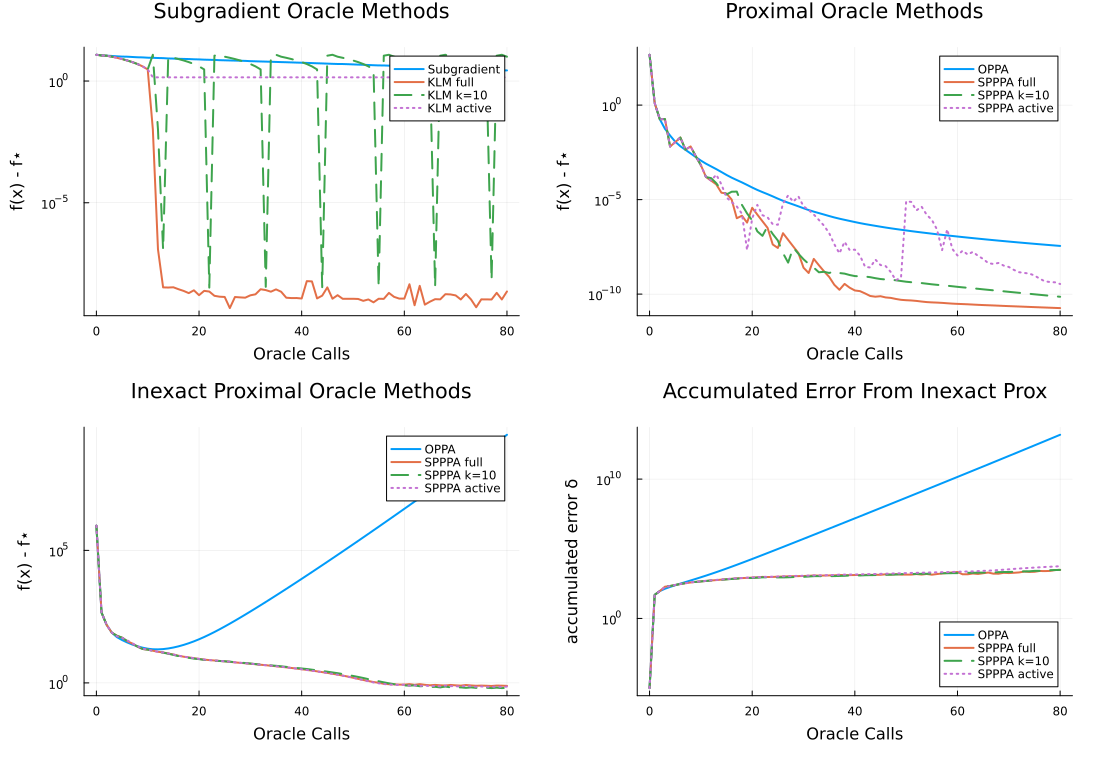

Saved figure to: numerics


(fig = Plot{Plots.GRBackend() n=16}, max_affine = (obj = (subgradient = [12.0, 11.365078744789985, 11.0, 10.73015748957997, 10.365078744789985, 10.095236234369956, 10.0, 9.73015748957997, 9.460314979159941, 9.365078744789985  …  3.285708703109867, 3.1904724687399115, 3.111102427059791, 3.0952362343699558, 3.0158661926898365, 3.0, 2.920629958319882, 2.8253937239499263, 2.746023682269806, 2.7301574895799705], klm_full = [12.0, 11.184046247868196, 11.0, 10.0, 9.0, 8.0, 7.0, 6.0, 5.0, 4.0  …  1.0646292736282703e-9, 1.787743286740806e-9, 1.0659313431915507e-9, 5.089795251933538e-10, 1.0749321432967918e-9, 1.0715943687955587e-9, 1.0610214928874484e-9, 1.9890791236321093e-9, 1.0640928138627714e-9, 2.2681483358155674e-9], klm_k = [12.0, 11.184046247868196, 11.0, 10.0, 9.0, 8.0, 7.0, 6.0, 5.0, 4.0  …  8.0, 7.0, 6.0, 5.0, 4.0, 3.0, 6.536788887956391e-9, 11.0, 12.0, 10.0], klm_active = [12.0, 11.184046523281392, 11.0, 10.0, 9.0, 8.0, 7.0, 6.0, 5.0, 4.0  …  1.4185585071515563, 1.4185584109017864, 

In [6]:
run_updated_tests(
    rotated_h_min=1e-5,
    rotated_h_max=1e4,
    rotated_L=5.0,
    inexact_inner_iters=80,
    cert_iters=500,
)